# ITER plasma evolution: a vertical displacement event (2D axisymmetric)

This notebook follows `tests/ITER_2D_evol`: the 15 MA equilibrium of the previous tutorial evolves for 0.63 s
while its poloidal beta drops from 0.68 to 0.23, at nearly constant current. Losing pressure, the plasma loses the
equilibrium imposed by the (fixed) coil currents and drifts vertically: a **vertical displacement event** (VDE).
The motion induces eddy currents in the vessel, which oppose it and set its speed; the plasma moves up, its X point
disappears, and it ends against the wall (a *limited* plasma).

**The coupled problem.** At each time step the field is a transient eddy-current solution (backward Euler):
$\nabla\times\nu\nabla\times A + \sigma\,\partial_t A = J_s$ in 2D, with $\sigma$ in the passive structures and
the plasma current density $J_s$ from the Grad-Shafranov profile, as in the equilibrium. `evolution_solve()` runs
the Picard iteration of the equilibrium **inside the time step**: each iteration recomputes the plasma current
from the last flux and re-solves *the same step* (same $t$, same previous state), until $\psi$ converges. The plasma
current and the eddy currents are thus found together, implicitly. Unlike the equilibrium there is no position
control: the plasma goes where the fields take it. The coil currents stay as they were (the model imposes their
current densities, as if ideal power supplies kept them constant).

The run takes about 2 minutes (the equilibrium, then 22 time steps of 30 ms). Theory: *Theory - Plasma
equilibrium and evolution*.

In [1]:
import os, shutil, tempfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv

import pytec3d
from pytec3d import Solver, selection
from pytec3d import mesh as meshes

pv.set_jupyter_backend("static")          # images in the notebook; "trame" gives interactive views
pytec3d.set_log_level("ERROR")            # warnings ("No loads" at every voltage-driven step...) stay in the job log

CASE = Path("../../tests/ITER_2D_evol").resolve()
WORK = Path(tempfile.mkdtemp(prefix="pytec3d_ITER_2D_evol_"))
for name in ("ITER_2D_evol.vtu", "model_data.json"):
    shutil.copy(CASE / name, WORK / name)
os.chdir(WORK)
print("working in a temporary folder:", WORK.name)

import contextlib, io
def quietly():
    """Keep the report tables that the solver prints (run provenance, run summary) out of the notebook: they are in
    the job log <model name>.log of the working folder."""
    return contextlib.redirect_stdout(io.StringIO())

import json, subprocess, sys, time
from pytec3d import Algorithm, Model, element_library

from matplotlib.collections import PolyCollection
from matplotlib.tri import Triangulation

def polygons(grid, mask=None):
    """The (R, Z) polygons of the cells of a 2D grid (all of them, or those where mask is True)."""
    g = pv.wrap(grid)
    points, conn, offset = g.points[:, :2], g.cell_connectivity, g.cell_offsets
    ids = np.arange(g.n_cells) if mask is None else np.flatnonzero(mask)
    return [points[conn[offset[i]:offset[i + 1]]] for i in ids]

def fill(ax, grid, mask, values=None, **kwargs):
    """Draw cells: one colour (facecolor=...) or coloured by the cell values (cmap=..., clim=...)."""
    collection = PolyCollection(polygons(grid, mask), **kwargs)
    if values is not None:
        collection.set_array(np.asarray(values)[mask])
    ax.add_collection(collection)
    return collection

def triangulation(grid):
    """The grid as matplotlib triangles over its points (for contours of point arrays such as PSI)."""
    t = pv.wrap(grid).triangulate()
    return Triangulation(t.points[:, 0], t.points[:, 1], t.cells.reshape(-1, 4)[:, 1:])

def frame(ax, r=(0.0, 13.0), z=(-9.0, 9.0)):
    ax.set_xlim(*r); ax.set_ylim(*z); ax.set_aspect("equal"); ax.set_xlabel("R [m]"); ax.set_ylabel("Z [m]")

working in a temporary folder: pytec3d_ITER_2D_evol_jozcf8g8


## The initial equilibrium

The evolution starts from the converged equilibrium. We run the test macro `tests/ITER_2D/macro.py` itself, in a
sub-folder of the working folder (about 10 s), and take its output: `output/ITER_2D_out_<n>.vtu`, the most recent
of that series, as the evolution macro does. (The previous tutorial explains this computation.)

In [2]:
EQ = WORK / "ITER_2D"
EQ.mkdir()
for name in ("ITER_2D.vtu", "model_data.json", "macro.py"):
    shutil.copy(CASE.parent / "ITER_2D" / name, EQ / name)
started = time.perf_counter()
run = subprocess.run([sys.executable, "macro.py"], cwd=EQ, capture_output=True, text=True)
assert run.returncode == 0, run.stderr[-3000:]
eq_file = max(EQ.glob("output/ITER_2D_out_*.vtu"), key=os.path.getmtime)
print(f"equilibrium computed in {time.perf_counter() - started:.0f} s:", eq_file.name)
equilibrium = Model.read_model(str(eq_file), reset_arrays=False)

equilibrium computed in 9 s: ITER_2D_out_29.vtu


## The evolution model

`ITER_2D_evol.vtu` is the same mesh as the equilibrium (same cells, same component arrays), with a third TYPE: 24,
`SOLID_CONDUCTOR`, on the **passive structures**: the vacuum vessel and its supports are **solid conductors**,
massive steel (rho = 8e-7 Ohm m) in which the eddy currents are computed. In 2D a solid conductor has no electric
unknown: its current density is $-\sigma\,\partial_t A$, the current of a toroidally closed shell. The coils and the
vacuum chamber stay `STRANDED_CONDUCTOR` (imposed `Js`).

In [3]:
solver = Solver(log_file="ITER_2D_evol.log")
algorithm = Algorithm(solver)
solver.read_model("ITER_2D_evol.vtu")
solver.model.read_json("model_data.json")
mesh = solver.model.mesh
grid = pv.wrap(mesh)
data = json.load(open("model_data.json"))
domains = dict(enumerate(element_library.domains()))
types = grid.cell_data["TYPE"]
for tid in np.unique(types):
    row, rho = data["element_types"][str(tid)], data["materials"][str(tid)]["rho"][0][0]
    print(f"TYPE {tid}: {domains[row['option1']]:26s} {np.sum(types == tid):5d} cells, rho = {rho:g} Ohm m")
structures = types == 24
area = grid.cell_data["cell_volume"]
print("passive structures = PASSIVE_STRUCTURES cells:", np.array_equal(structures, grid.cell_data["PASSIVE_STRUCTURES"] == 1))

TYPE 21: NON_CONDUCTING              6000 cells, rho = 1 Ohm m
TYPE 23: STRANDED_CONDUCTOR          4144 cells, rho = 1 Ohm m
TYPE 24: SOLID_CONDUCTOR             1096 cells, rho = 8e-07 Ohm m
passive structures = PASSIVE_STRUCTURES cells: True


How fast can the vessel react? A rough time constant of a thin toroidal shell is $\tau \approx \mu_0\sigma\,d\,b$
(thickness $d$, minor radius $b$). It sets the time step: the vertical motion of an unstable plasma grows on the
time scale of the vessel currents, here a few hundred milliseconds, so steps of 30 ms resolve it, with backward
Euler (theta = 1) for stability.

In [4]:
d, b = 0.06, 2.5              # ITER vessel: about 60 mm of steel per shell, 2-2.5 m from the plasma
print(f"tau ~ mu0 sigma d b = {4e-7 * np.pi / 8e-7 * d * b * 1e3:.0f} ms")

tau ~ mu0 sigma d b = 236 ms


## Initial state

1. `algorithm.vacuum_chamber_mesh = equilibrium.mesh`: the algorithm works on a copy of the VACUUM_CHAMBER cells of
   the equilibrium, with its flux and plasma region, which is where it looks for the plasma at the first iteration.
2. $A_z = 0$ on the external boundary, as in the equilibrium.
3. The current densities of the equilibrium (coils and plasma) become the `Js` of the evolution model: the `Js` of
   the equilibrium output (its `Jt` holds the same values on the stranded conductors).

In [5]:
algorithm.vacuum_chamber_mesh = equilibrium.mesh
with quietly():
    solver.load_model_into_solver()
selection.select_all(mesh)
selection.nsel_ext(mesh)
selection.set_value_on_selection(mesh, "_A", 0.0, 2)

meshes.array_values(mesh, "Js", "elem")[:] = meshes.array_values(equilibrium.mesh, "Js", "elem")
meshes.get_array(mesh, "Js", "elem").Modified()
js = meshes.array_values(mesh, "Js", "elem")[:, 2]
print(f"plasma current {(js * area)[grid.cell_data['VACUUM_CHAMBER'] == 1].sum() / 1e6:.2f} MA, "
      f"coils {(js * area)[grid.cell_data['COILS'] == 1].sum() / 1e6:.2f} MA-turns")

algorithm.input_parameters.update(R0=6.2, alpha_mp=1.0001, alpha_np=0.83197, AF0=5.3 * 6.2,
                                  tolerance_value=1e-4, max_picard_iterations=70)

plasma current 15.00 MA, coils -54.13 MA-turns


## The scenario

`tests/files` holds the waveforms of $I_p(t)$ and $\beta_p(t)$, sampled every 0.2 ms up to 0.636 s. The test
macro uses every fifth sample (1 ms steps, 637 steps); here we take one every 150 (30 ms), 22 steps. At $t = 0$
the plasma loses part of its energy ($\beta_p$ 0.68 -> 0.58 within 0.4 ms, $I_p$ -110 kA), then $\beta_p$ keeps
decaying while $I_p$ recovers slowly to 15.2 MA. The last samples are the **thermal quench** at 0.6356 s
($\beta_p \to 0$, $I_p$ starting to fall; `plasma_current.txt` continues with the current quench beyond the last
time): we stop at 0.63 s, just before it.

22 steps, dt = [0.03] s


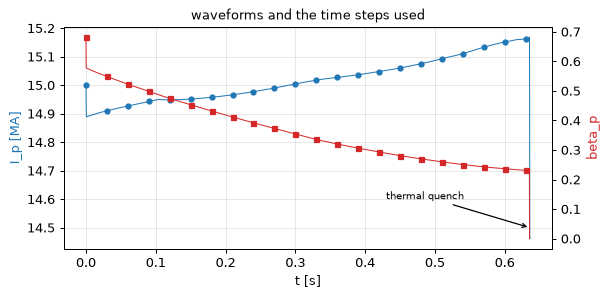

In [6]:
files = CASE.parent / "files"
t_all = np.loadtxt(files / "time_steps.txt")
ip_all = np.loadtxt(files / "plasma_current.txt")[:len(t_all)]
bp_all = np.loadtxt(files / "beta_p.txt")
pick = np.concatenate(([0], np.arange(150, len(t_all), 150)))
times, ip, bp = t_all[pick], ip_all[pick], bp_all[pick]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(t_all, ip_all / 1e6, color="C0", lw=0.8); ax.plot(times, ip / 1e6, "o", color="C0", ms=4)
ax.set_xlabel("t [s]"); ax.set_ylabel("I_p [MA]", color="C0")
ax2 = ax.twinx(); ax2.plot(t_all, bp_all, color="C3", lw=0.8); ax2.plot(times, bp, "s", color="C3", ms=4)
ax2.set_ylabel("beta_p", color="C3"); ax.grid(alpha=0.3); ax.set_title("waveforms and the time steps used", fontsize=10)
ax.annotate("thermal quench", (0.636, 14.5), xytext=(0.43, 14.6), arrowprops={"arrowstyle": "->"}, fontsize=8)
plt.show()
print(len(times), "steps, dt =", np.unique(np.round(np.diff(times), 6)), "s")

## The time loop

* Step 0 is **static**, at a tiny time: it re-solves the equilibrium field with the copied currents (no eddy
  currents) and gives the initial state of the transient. The evolution solve of the first call only initializes
  the flux, with one solve.
* Then every step is transient, theta = 1, with the waveform values of $I_p$ and $\beta_p$ of its end time. The
  matrix is factorized once at the first transient step and reused (constant dt).

After every step we record the status (axis, X point, configuration, Picard iterations), the current induced in
the structures ($\sum J_t\,a$ over TYPE 24: their `Jt` is all eddy current, they have no `Js`), the current
centroid of the plasma, and the flux of the vacuum chamber for the pictures.

In [7]:
solver.time_step["theta"] = 1.0
chamber = algorithm.vacuum_chamber_mesh
c_area = meshes.array_values(chamber, meshes.SIZES_ARRAY, "elem")
c_centroid = meshes.array_values(chamber, meshes.CENTROIDS_ARRAY, "elem")
records, started = [], time.perf_counter()
for k, t in enumerate(times):
    solver.time_step["transient_effects"] = k > 0
    solver.time_step["time"] = t if k > 0 else 1e-10
    algorithm.input_parameters.update(plasma_current=ip[k], beta_p=bp[k])
    with quietly():
        algorithm.evolution_solve()
    st = dict(algorithm.status)
    psi_c = meshes.array_values(chamber, "PSI", "node")
    if k == 0:      # the first call only solves: no status yet, the axis is where the flux is largest
        st.update(magnetic_axis=tuple(meshes.points(chamber)[np.argmax(psi_c)]), separatrix_configuration="initial")
    jt = meshes.array_values(mesh, "Jt", "elem")
    jp = meshes.array_values(chamber, "Js", "elem")[:, 2] * c_area
    records.append({"t": t, "iterations": st["picard_iteration"], "configuration": st["separatrix_configuration"],
                    "axis": st["magnetic_axis"][:2], "x_point": st["x_point"][:2],
                    "limiter": st["limiter_point"][:2], "psi_b": st["psi_min"],
                    "centroid": (jp @ c_centroid[:, :2]) / jp.sum() if jp.sum() else (np.nan, np.nan),
                    "vessel": (jt[structures, 2] * area[structures]).sum(),
                    "vessel_j": jt[structures, 2].copy(),
                    "psi": psi_c.copy()})
    r = records[-1]
    print(f"step {k:2d}  t = {r['t']:.2f} s  {r['iterations']:2d} Picard it.  axis ({r['axis'][0]:.2f}, {r['axis'][1]:+.2f}) m"
          f"  {r['configuration']:8s}  {st['plasma_element_count']:4d} plasma cells"
          f"  vessel {r['vessel'] / 1e6:+.2f} MA   [{time.perf_counter() - started:.0f} s]")

step  0  t = 0.00 s   1 Picard it.  axis (6.52, +0.59) m  initial      0 plasma cells  vessel +0.00 MA   [1 s]
step  1  t = 0.03 s  14 Picard it.  axis (6.44, +0.55) m  X-point   2715 plasma cells  vessel +0.10 MA   [4 s]
step  2  t = 0.06 s  14 Picard it.  axis (6.44, +0.55) m  X-point   2711 plasma cells  vessel +0.10 MA   [7 s]
step  3  t = 0.09 s  14 Picard it.  axis (6.44, +0.55) m  X-point   2729 plasma cells  vessel +0.11 MA   [9 s]
step  4  t = 0.12 s  15 Picard it.  axis (6.44, +0.55) m  X-point   2733 plasma cells  vessel +0.12 MA   [12 s]
step  5  t = 0.15 s  16 Picard it.  axis (6.44, +0.55) m  X-point   2743 plasma cells  vessel +0.14 MA   [17 s]
step  6  t = 0.18 s  18 Picard it.  axis (6.40, +0.64) m  X-point   2730 plasma cells  vessel +0.16 MA   [23 s]
step  7  t = 0.21 s  18 Picard it.  axis (6.31, +0.60) m  X-point   2722 plasma cells  vessel +0.17 MA   [27 s]
step  8  t = 0.24 s  20 Picard it.  axis (6.31, +0.60) m  X-point   2742 plasma cells  vessel +0.19 MA   [32

## Results

### Trajectory and vessel current

the plasma becomes limited at t = 0.36 s (dotted line)


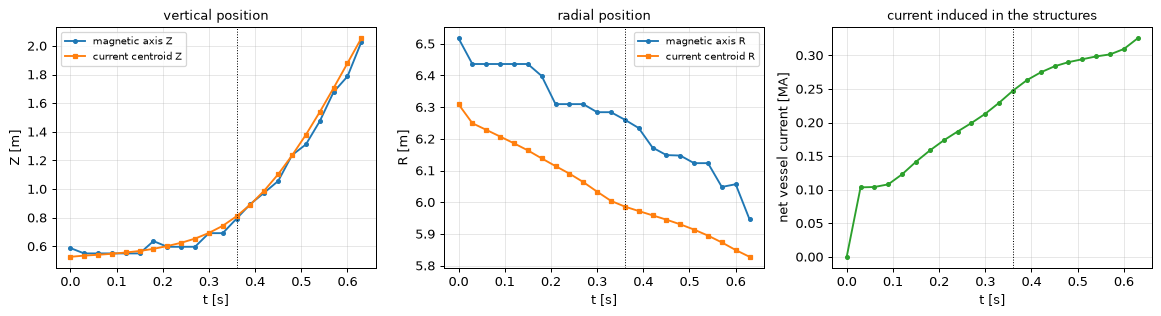

In [8]:
t = np.array([r["t"] for r in records])
axis = np.array([r["axis"] for r in records]); centroid = np.array([r["centroid"] for r in records])
vessel = np.array([r["vessel"] for r in records]) / 1e6
limited = np.array([r["configuration"] == "limiter" for r in records])
switch = t[np.argmax(limited)] if limited.any() else None

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
ax = axes[0]
ax.plot(t, axis[:, 1], "o-", ms=3, label="magnetic axis Z"); ax.plot(t, centroid[:, 1], "s-", ms=3, label="current centroid Z")
ax.set_ylabel("Z [m]"); ax.legend(fontsize=8)
ax = axes[1]
ax.plot(t, axis[:, 0], "o-", ms=3, label="magnetic axis R"); ax.plot(t, centroid[:, 0], "s-", ms=3, label="current centroid R")
ax.set_ylabel("R [m]"); ax.legend(fontsize=8)
ax = axes[2]
ax.plot(t, vessel, "o-", ms=3, color="C2"); ax.set_ylabel("net vessel current [MA]")
for ax in axes:
    ax.set_xlabel("t [s]"); ax.grid(alpha=0.3)
    if switch is not None:
        ax.axvline(switch, color="k", ls=":", lw=0.8)
axes[0].set_title("vertical position", fontsize=10); axes[1].set_title("radial position", fontsize=10)
axes[2].set_title("current induced in the structures", fontsize=10)
plt.tight_layout(); plt.show()
if switch is not None:
    print(f"the plasma becomes limited at t = {switch:.2f} s (dotted line)")

What happens:

* **first step**: the loss of pressure reduces the outward force on the plasma ring (the coil currents, set for
  $\beta_p$ = 0.68, now push too much inwards): the plasma moves inwards by about 8 cm, and keeps drifting inwards
  as $\beta_p$ decays (the current centroid by 0.5 m in all). The plasma current falls by 90 kA, and the vessel
  picks up a co-current of about 0.1 MA that keeps the flux it encloses;
* **vertical drift**: an elongated plasma in the field of fixed coils is vertically unstable. The plasma rises
  slowly at first (15 cm in 0.3 s) and then faster and faster (1.3 m in the last 0.3 s): an exponential growth whose
  rate is set by the vessel, since the plasma can only move as fast as the eddy currents that oppose the motion
  decay. Upper structures get a counter-current, lower ones a co-current (see the snapshots);
* **limited plasma**: from 0.36 s the X point is no longer the boundary: the last closed surface touches the wall
  (first the inner wall, then the top), and the plasma shrinks as it is scraped off against it.

The magnetic axis (the node of largest $\psi$, which moves in steps of the mesh) and the current centroid move
together; the centroid is what the magnetic diagnostics of a machine measure.

### Picard iterations per step

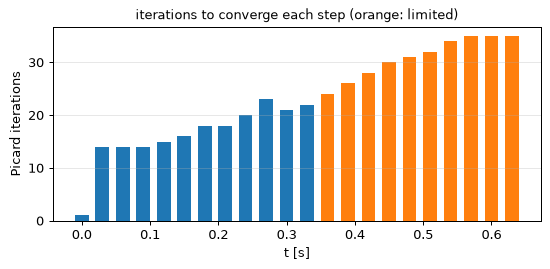

In [9]:
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(t, [r["iterations"] for r in records], width=0.02, color=np.where(limited, "C1", "C0"))
ax.set_xlabel("t [s]"); ax.set_ylabel("Picard iterations"); ax.grid(alpha=0.3, axis="y")
ax.set_title("iterations to converge each step (orange: limited)", fontsize=10); plt.show()

Each Picard iteration is one solve with the factorized matrix (a forward-backward substitution), so the cost of
a step is proportional to its iterations. Steps converge slowly when the plasma moves a lot during the step or
changes configuration: smaller time steps reduce both the motion per step and the iterations.

### Snapshots

The separatrix (boundary flux surface) at a few times, over the eddy current density in the structures at the
same time (red: co-current, blue: counter-current, with the sign of the plasma current). The `PLASMA` cell array of
the chamber marks the plasma at each step: the cells inside the boundary of the current, the X-point surface of a
diverted plasma or the limiter surface of a limited one.

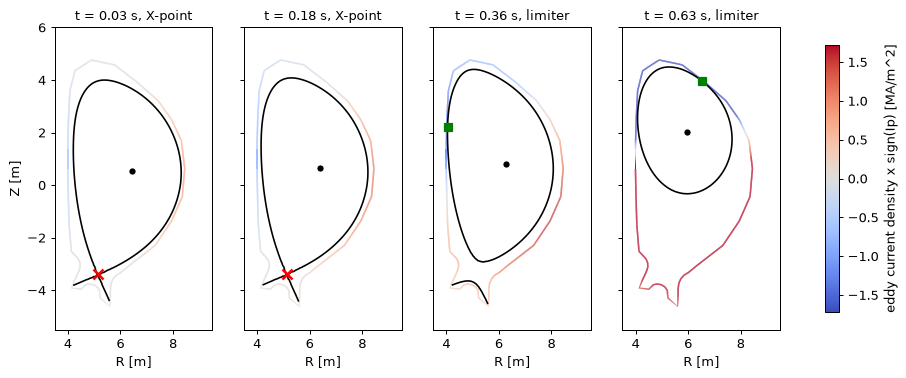

In [10]:
chamber_tri = triangulation(chamber)
shown = [1, 6, 12, len(records) - 1]
fig, axes = plt.subplots(1, len(shown), figsize=(13, 5.5), sharey=True)
jmax = max(np.abs(records[k]["vessel_j"]).max() for k in shown) / 1e6
sign = np.sign(ip[0])
for ax, k in zip(axes, shown):
    r = records[k]
    pc = fill(ax, mesh, structures, np.zeros(grid.n_cells), cmap="coolwarm", edgecolor="none")
    values = np.zeros(grid.n_cells); values[structures] = sign * r["vessel_j"] / 1e6
    pc.set_array(values[structures]); pc.set_clim(-jmax / 3, jmax / 3)
    ax.tricontour(chamber_tri, r["psi"], levels=[r["psi_b"]], colors="k", linewidths=1.3, linestyles="solid")
    ax.plot(*r["axis"], "ko", ms=4)
    if r["configuration"] == "X-point":
        ax.plot(*r["x_point"], "rx", ms=8, mew=2)
    else:
        ax.plot(*r["limiter"], "gs", ms=6)
    frame(ax, r=(3.5, 9.5), z=(-5.5, 6.0)); ax.set_title(f"t = {r['t']:.2f} s, {r['configuration']}", fontsize=10)
    if ax is not axes[0]:
        ax.set_ylabel("")
fig.colorbar(pc, ax=axes, shrink=0.7, label="eddy current density x sign(Ip) [MA/m^2]")
plt.show()

## A 3D view of the last step

The vessel structures revolved around the machine axis (240 degrees), coloured by the induced current density,
and the plasma (its current-carrying cells) at the end of the event, pressed against the top of the chamber.

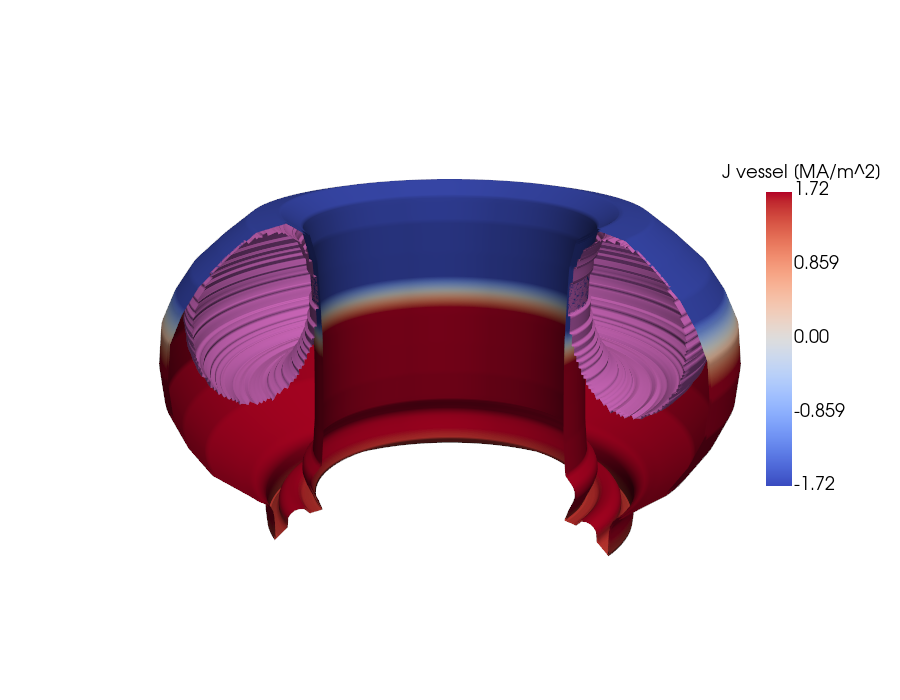

In [11]:
def revolved(surface, angle=240, capping=False):
    """The surface of revolution of the boundary of a 2D region (its point data carried around)."""
    outline = surface.extract_feature_edges(boundary_edges=True, feature_edges=False, manifold_edges=False,
                                            non_manifold_edges=False)
    return outline.extrude_rotate(resolution=80, angle=angle, rotation_axis=(0, 1, 0), capping=capping)

last = grid.copy()
last.cell_data["J vessel [MA/m^2]"] = sign * meshes.array_values(mesh, "Jt", "elem")[:, 2] / 1e6
wall = last.threshold(value=(24, 24), scalars="TYPE").extract_surface(algorithm=None).cell_data_to_point_data()
current = pv.wrap(chamber).copy()
current.cell_data["J_phi"] = meshes.array_values(chamber, "Js", "elem")[:, 2]
plasma_now = current.extract_cells(np.flatnonzero(current.cell_data["J_phi"] != 0)).extract_surface(algorithm=None)
pl = pv.Plotter(window_size=(900, 700))
pl.add_mesh(revolved(wall), scalars="J vessel [MA/m^2]", cmap="coolwarm", clim=[-jmax / 3, jmax / 3],
            smooth_shading=True, scalar_bar_args={"vertical": True, "position_x": 0.85, "position_y": 0.3})
pl.add_mesh(revolved(plasma_now, capping=True), color="orchid", smooth_shading=True)
pl.camera_position = [(22, 12, 30), (0, 0.5, 0), (0, 1, 0)]
pl.show()
with quietly():
    solver.close()

## Going further

* **The full test**: `tests/ITER_2D_evol/macro.py` runs the same scenario with 1 ms steps and writes every step to
  `./output` (open the series in ParaView; see *User manual - ParaView*).
* **Halo currents**: when the plasma is limited, `halo_delta1`, `halo_delta2`, `t0_halo` define a halo region outside
  the last closed surface, whose poloidal currents close through the wall (3D models, `ITER_3D_evol*`).
* **3D structures**: `ITER_3D_evol*` couple the same 2D plasma with a 3D mesh of the vessel; the algorithm projects
  the plasma current around the torus and averages the 3D flux back to the 2D chamber.
* **Coils with power supplies**: modelling the coils as `STRANDED_COIL` with their circuit equation (terminal
  voltages) lets their currents react to the plasma motion as well (`ITER_2D_evol_coils`).